# 3. Cross-validation and replication of niches

This vignette evaluates GRASS-MIL by nested cross-validation (one image per
outer fold), analyses the niches of a fold model on the tiles it never saw, and
asks which niches recur across the fold models. It reuses the encoder pretrained
in vignette 2.

With three images, the folds are small: the numbers illustrate the procedure,
not the performance of the method.

In [1]:
import json
import pathlib
import subprocess

import pandas as pd
from IPython.display import Image, display

WORK = pathlib.Path("vignette_work").resolve()
DATA = WORK / "data"
COHORT = json.loads((WORK / "cohort.json").read_text())  # written by vignette 1

# Fine-tuning on a handful of tiles: a stronger probe penalty (the default C=1
# suits tens of thousands of ego-graphs) and more optimizer steps per epoch.
SMALL_DATA = ["finetune.probe.C=0.01", "finetune.hyperbatch_size=4"]


def run(command, *overrides):
    """Run a grass-mil command; show the end of its log if it fails.

    Commands that read the cohort (train, nested-cv, extract) get its settings;
    the analysis commands read a cell cache instead.
    """
    cohort = (
        COHORT["overrides"]
        if command in ("grass-mil-train", "grass-mil-nested-cv", "grass-mil-extract")
        else []
    )
    result = subprocess.run([command, *cohort, *overrides], capture_output=True, text=True)
    if result.returncode:
        print(result.stderr[-4000:])
        raise RuntimeError(f"{command} failed")


ENCODER = WORK / "pretrain" / "checkpoints" / "last.ckpt"

## Nested cross-validation

For every outer fold, the other two images are split into inner folds (here
`inner_k=2`, one image each); every inner run reports its best epoch, and the
model is refitted on both images for the median of those epochs and scored on
the held-out image.

In [2]:
run(
    "grass-mil-nested-cv",
    f"model.init_from_ckpt={ENCODER}",
    *SMALL_DATA,
    f"nested_cv.folds_file={DATA / 'folds.json'}",
    "nested_cv.inner_k=2",
    "trainer.max_epochs=20",
    "trainer.min_epochs=5",
    f"hydra.run.dir={WORK / 'nested_cv'}",
)
CV = WORK / "nested_cv"
summary = json.loads((CV / "nested_cv_summary.json").read_text())
print(f"AUROC per held-out image: {[round(v, 3) for v in summary['fold_values']]}")
print(
    f"mean ± s.d.: {summary['mean']:.3f} ± {summary['sd']:.3f}; pooled: {summary['pooled']['auroc']:.3f}"
)
pd.read_csv(CV / "oof_predictions.csv").round(3).head()

AUROC per held-out image: [0.917, 0.971, 0.909]
mean ± s.d.: 0.932 ± 0.034; pooled: 0.791


,outer,unit_id,prob_0,prob_1,pred,label,region_id,sample_id,patient_id
0,0,point16_tile000,0.410,0.590,1,1,point16,point16,point16
1,0,point16_tile001,0.700,0.300,0,1,point16,point16,point16
2,0,point16_tile002,0.466,0.534,1,1,point16,point16,point16
3,0,point16_tile003,0.816,0.184,0,1,point16,point16,point16
4,0,point16_tile004,0.833,0.167,0,1,point16,point16,point16


## Per-cell outputs of every fold model

Each fold model scores every tile; the cache records which tiles it held out.

In [3]:
run(
    "grass-mil-extract",
    f"extract.nested_cv_summary={CV / 'nested_cv_summary.json'}",
    f"extract.output_dir={WORK / 'cv_cells'}",
    f"hydra.run.dir={WORK / 'cv_extract'}",
)
sorted(p.name for p in (WORK / "cv_cells").iterdir())

['fold0', 'fold1', 'fold2']

## Niches of one fold model, on its held-out tiles

By default `grass-mil-niches` analyses the units the model did not train on;
as in vignette 2, leaf selection suits the small number of cells. The margin
intervals resample patients; this fold holds out one image, a single patient, so
they are not defined (NaN).

,niche,share,association,margin,margin_lo,margin_hi,composition
0,Niche 1,0.065,1.000,-5.817,NaN,NaN,"Epithelial 35%, Tcell_CD8 33%, Tcell_CD4 15%"
1,Niche 2,0.044,0.956,-6.179,NaN,NaN,"Tcell_CD8 36%, Tcell_CD4 33%, Endothelial 9%"
2,Niche 3,0.163,0.886,-6.842,NaN,NaN,"Tcell_CD4 30%, Tcell_CD8 30%, Fibroblast 16%"
3,Niche 4,0.029,1.000,-8.056,NaN,NaN,"Tcell_CD4 27%, Tcell_CD8 27%, Epithelial 20%"
4,Niche 5,0.034,0.029,-8.239,NaN,NaN,"Fibroblast 43%, Tcell_CD4 23%, Imm_other 17%"
5,Niche 6,0.041,1.000,-8.627,NaN,NaN,"Tcell_CD8 43%, Tcell_CD4 40%, Endothelial 5%"
6,Niche 7,0.033,0.382,-11.093,NaN,NaN,"Epithelial 91%, Imm_other 9%"
7,Niche 8,0.100,0.088,-12.051,NaN,NaN,"Epithelial 71%, Imm_other 19%, Fibroblast 3%"
8,Niche 9,0.031,0.000,-13.107,NaN,NaN,"Fibroblast 56%, Imm_other 19%, Tcell_CD4 19%"
9,Background,0.459,0.736,-8.788,NaN,NaN,"Tcell_CD4 23%, Tcell_CD8 23%, Epithelial 16%"


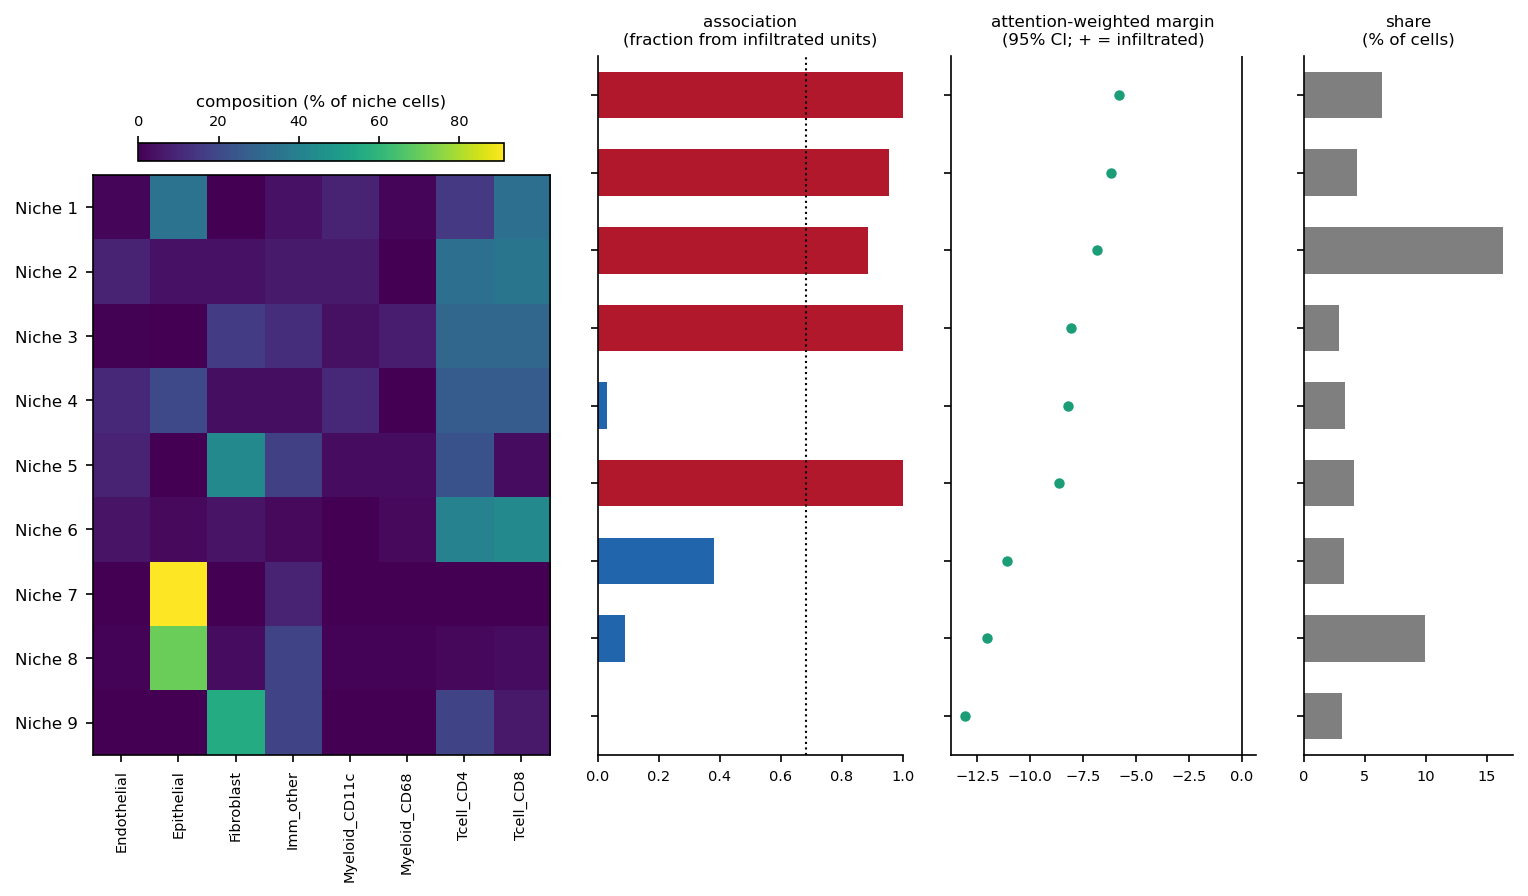

In [4]:
run(
    "grass-mil-niches",
    f"cells_dir={WORK / 'cv_cells' / 'fold0'}",
    "clustering.min_cluster_size=30",
    "clustering.selection=leaf",
    "positive_name=infiltrated",
    f"hydra.run.dir={WORK / 'cv_niches'}",
)
display(
    pd.read_csv(WORK / "cv_niches" / "niches.csv")[
        ["niche", "share", "association", "margin", "margin_lo", "margin_hi", "composition"]
    ].round(3)
)
display(Image(WORK / "cv_niches" / "figures" / "niche_panel.png"))

## Replication across fold models (optional)

Every fold model has its own embedding, so its niches are discovered on its own
held-out tiles. `grass-mil-metaclusters` matches niches of different models by
their cell-type composition; a metacluster found by at least `min_models`
models is replicated.

,metacluster,n_models,replicated,margin,association_vs_base,composition
0,M1,3,True,-6.358,-0.126,"Epithelial 36%, Tcell_CD4 26%, Tcell_CD8 16%"
1,M2,3,True,-5.056,0.197,"Tcell_CD4 32%, Tcell_CD8 23%, Imm_other 17%"
2,M3,3,True,-5.962,0.238,"Tcell_CD4 21%, Tcell_CD8 17%, Imm_other 15%"
3,M4,3,True,-6.107,0.018,"Tcell_CD4 28%, Fibroblast 22%, Imm_other 18%"
4,M5,3,True,-5.054,0.161,"Tcell_CD4 39%, Tcell_CD8 21%, Myeloid_CD68 13%"
5,M6,2,True,-0.435,0.204,"Tcell_CD4 45%, Tcell_CD8 23%, Imm_other 11%"
6,M7,2,True,-13.369,-0.314,"Epithelial 94%, Imm_other 6%, Endothelial 0%"
7,M8,2,True,-12.346,-0.396,"Epithelial 67%, Imm_other 15%, Fibroblast 4%"
8,M9,2,True,-13.010,-0.383,"Fibroblast 41%, Myeloid_CD68 19%, Imm_other 16%"
9,M10,2,True,-6.512,-0.238,"Epithelial 50%, Myeloid_CD68 14%, Tcell_CD4 14%"


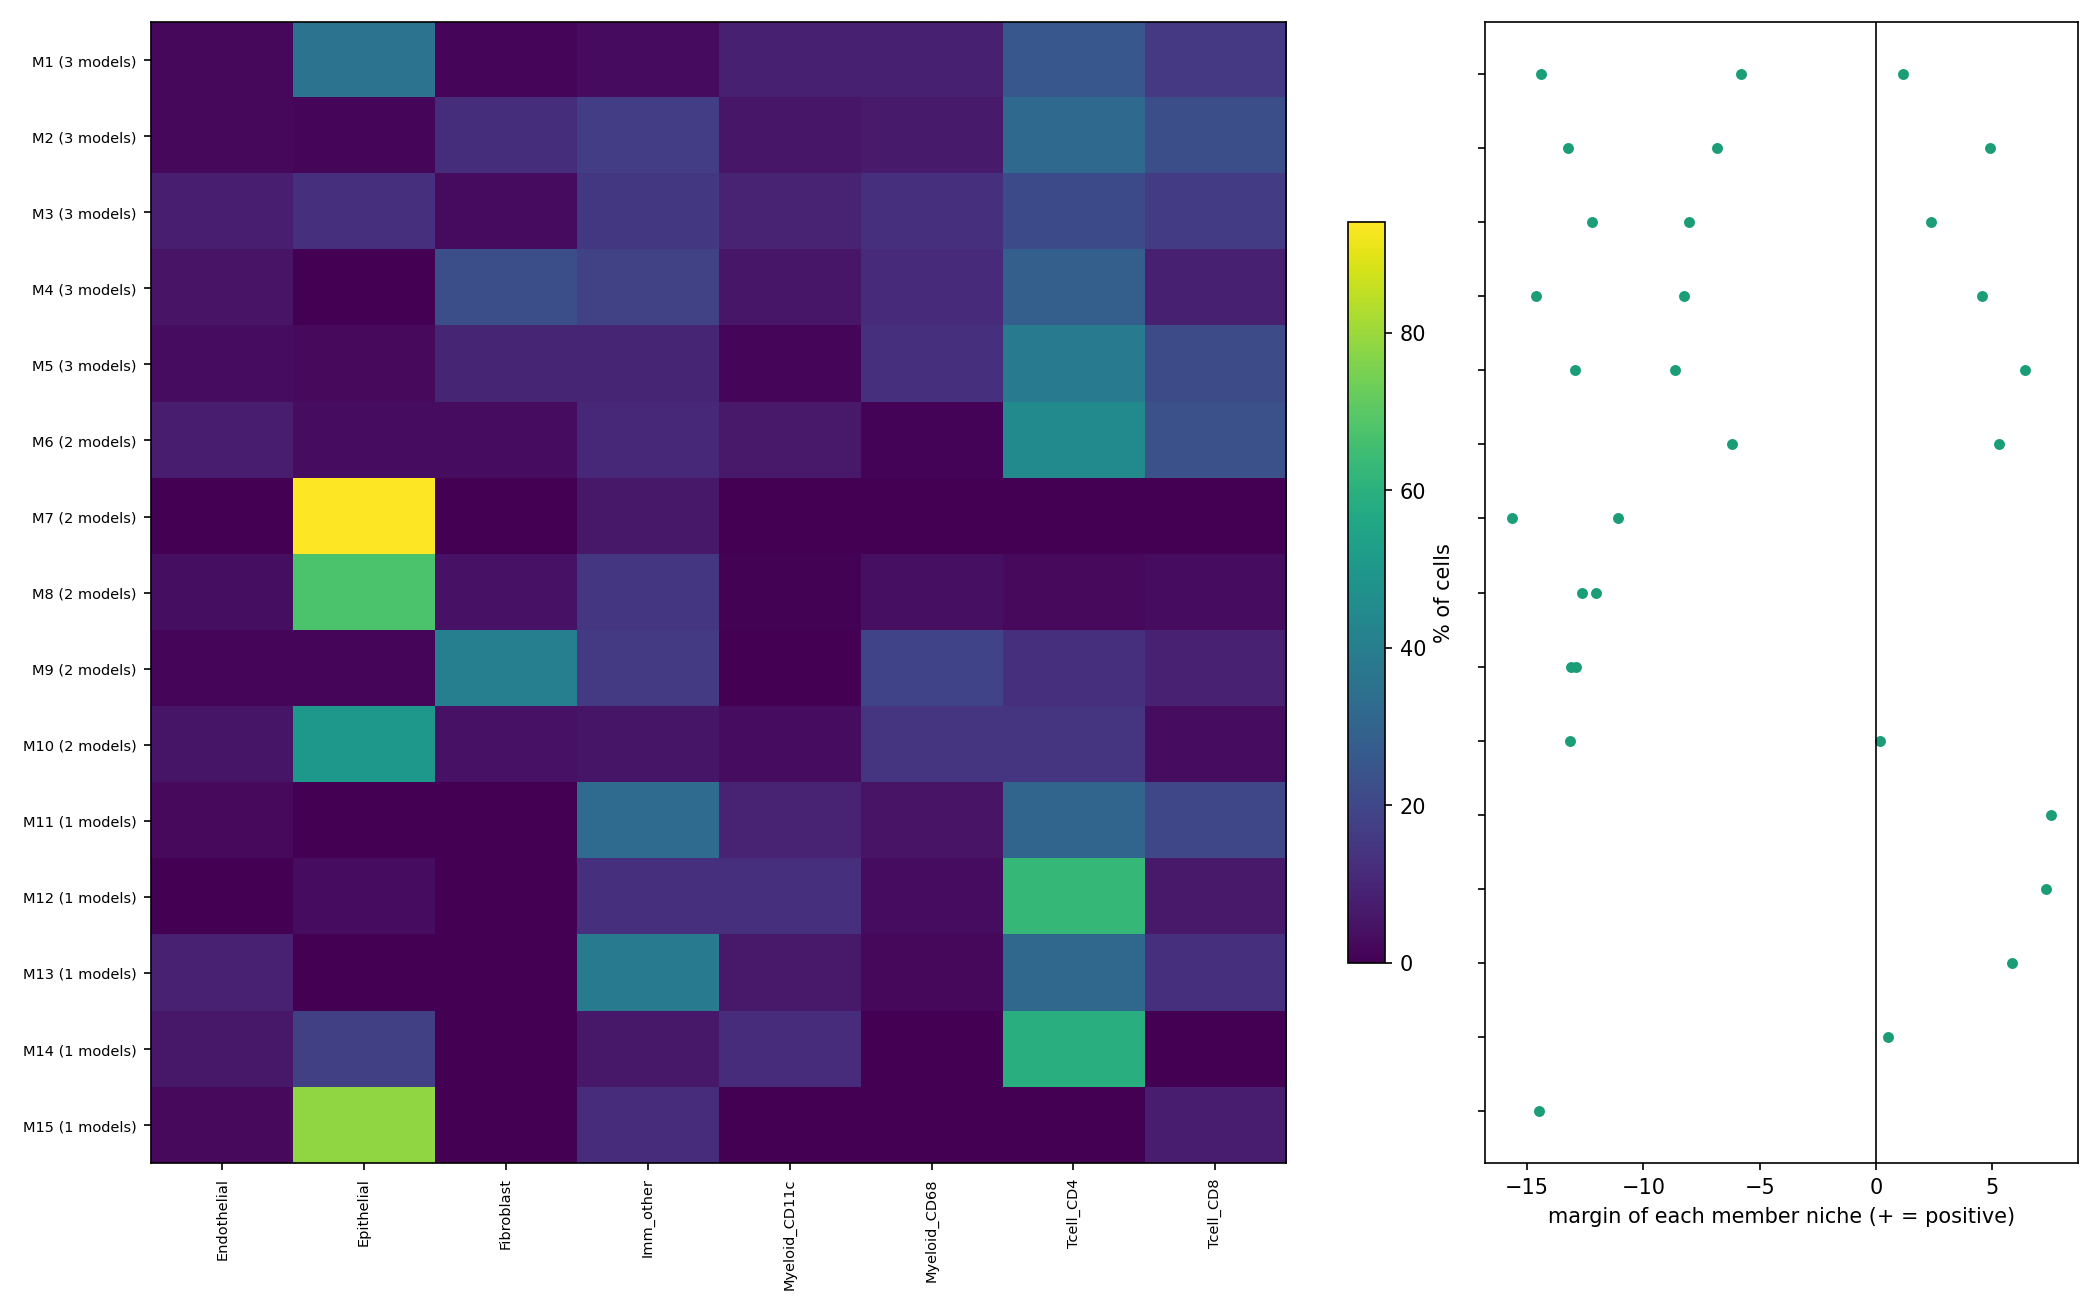

In [5]:
run(
    "grass-mil-metaclusters",
    f"cells_dir={WORK / 'cv_cells'}",
    "+clustering.min_cluster_size=30",
    "+clustering.selection=leaf",
    "match.min_models=2",
    "basis.k=6",
    f"hydra.run.dir={WORK / 'metaclusters'}",
)
META = WORK / "metaclusters"
display(
    pd.read_csv(META / "metaclusters.csv")[
        ["metacluster", "n_models", "replicated", "margin", "association_vs_base", "composition"]
    ].round(3)
)
display(Image(META / "metaclusters.png"))

## Model-free spatial statistics (optional)

The same cells, without a model: neighbourhood enrichment, cellular
neighbourhoods, and contacts and cross-L of epithelial cells with every other
type, compared between infiltrated and other tiles. With three images there
are too few patients to compare, so tiles are compared (`compare_by=unit`);
tiles of one image are not independent, so these p-values only illustrate the
output. On a cohort, patients are compared, each summarised by the mean over
its units.

In [6]:
run(
    "grass-mil-spatial-stats",
    f"cells_dir={WORK / 'cv_cells' / 'fold0'}",
    "reference=[Epithelial]",
    "compare_by=unit",
    "min_patients=3",
    f"hydra.run.dir={WORK / 'spatial_stats'}",
)
pd.read_csv(WORK / "spatial_stats" / "contacts_tests.csv").round(4).head(8)

,metric,n_pos,n_neg,mean_pos,mean_neg,auroc,p,diff,q
0,Epithelial->Epithelial,7,15,0.4995,0.8126,0.1905,0.0213,-0.3131,0.0945
1,Epithelial->Tcell_CD8,7,15,0.0967,0.0149,0.8000,0.0236,0.0818,0.0945
2,Epithelial->Tcell_CD4,7,15,0.1793,0.0355,0.7714,0.0462,0.1439,0.1232
3,Epithelial->Myeloid_CD68,7,15,0.0631,0.0430,0.3095,0.1590,0.0202,0.3180
4,Epithelial->Endothelial,7,15,0.0372,0.0177,0.6476,0.2826,0.0194,0.4522
5,Epithelial->Myeloid_CD11c,7,15,0.0527,0.0256,0.5810,0.5666,0.0271,0.7555
6,Epithelial->Fibroblast,7,15,0.0198,0.0077,0.4905,0.9674,0.0121,1.0000
7,Epithelial->Imm_other,7,15,0.0516,0.0430,0.5048,1.0000,0.0086,1.0000
